## Customer Retention Risk

# 1. Project Overview

Gymnasyum membutuhkan sistem yang dapat membantu tim mengidentifikasi customer yang mulai menunjukkan penurunan engagement dan berpotensi membutuhkan perhatian lebih awal. Prototype **Customer Retention Risk Dashboard** akan mengolah data profil dan aktivitas customer untuk menghasilkan risk score serta mengelompokkan customer ke dalam tiga kategori prioritas monitoring: **Active**, **Need Attention**, dan **At Risk**.

Sistem ini berfungsi sebagai alat bantu pengambilan keputusan bagi admin dan coach. Hasil klasifikasi bukan keputusan final mengenai kondisi customer dan tidak menggantikan pertimbangan tim Gymnasyum.

Karena data historis customer Gymnasyum belum tersedia, proyek menggunakan dataset publik, dataset eksternal, dan data dummy/sintetis yang terdokumentasi. Hasil model diposisikan sebagai prototype dan tidak diklaim sebagai prediksi churn aktual customer Gymnasyum.

## 1.1 Business Understanding

Dalam bisnis gym dan private coaching, mempertahankan customer agar terus menggunakan layanan merupakan hal penting bagi keberlangsungan bisnis. Customer dapat mengurangi atau menghentikan aktivitasnya karena frekuensi latihan menurun, sering tidak hadir, melakukan reschedule berulang kali, mendekati akhir paket, atau tidak merespons komunikasi admin.

Saat ini, data customer seperti profil, membership, attendance, frekuensi kunjungan, dan aktivitas latihan belum dimanfaatkan secara sistematis untuk membantu tim menemukan pola tersebut. Akibatnya, proses monitoring dan follow-up masih bergantung pada observasi serta ingatan admin atau coach.

Proyek ini mengusulkan prototype sistem pendukung keputusan yang mengolah data aktivitas customer menjadi informasi prioritas monitoring. Sistem akan mengidentifikasi pola yang berkaitan dengan penurunan engagement, menghasilkan risk score, menampilkan indikator pendukung, serta membantu admin menyiapkan draft follow-up.

Permasalahan bisnis utama yang ingin dibantu adalah:

> **Bagaimana Gymnasyum dapat mengidentifikasi customer yang mulai menunjukkan penurunan engagement secara lebih awal sehingga tim dapat menentukan prioritas monitoring dan follow-up?**

Sistem tidak dimaksudkan untuk menyatakan bahwa customer pasti akan berhenti. Kategori **Active**, **Need Attention**, dan **At Risk** hanya digunakan sebagai risk tier untuk membantu prioritas pemantauan dan tetap memerlukan peninjauan manusia.

Dataset yang digunakan berasal dari sumber publik, dataset eksternal, dan data sintetis karena data historis customer Gymnasyum belum tersedia. Oleh karena itu, hasil model tidak dapat dianggap sebagai bukti prediksi churn aktual di Gymnasyum.

## 1.2 Project Objectives

1. Menyiapkan dan membersihkan data profil serta aktivitas customer, termasuk membership, attendance, frekuensi kunjungan, dan aktivitas latihan.
2. Membangun fitur analitik customer-level seperti attendance rate, frekuensi kunjungan, hari sejak aktivitas terakhir, penggunaan membership, dan jumlah renewal.
3. Mengidentifikasi pola aktivitas yang berkaitan dengan penurunan engagement dan risiko dropout.
4. Membangun model atau risk scoring yang mengelompokkan customer ke dalam kategori **Active**, **Need Attention**, dan **At Risk**.
5. Membandingkan performa model dengan baseline menggunakan metrik yang sesuai, seperti precision, recall, F1-score, balanced accuracy, ROC-AUC, dan confusion matrix.
6. Menampilkan hasil klasifikasi beserta indikator pendukung agar dapat ditinjau dan dipahami oleh admin.
7. Menyediakan hasil model melalui inference API serta menghasilkan ringkasan kondisi dan draft follow-up yang dapat disunting admin.
8. Mendokumentasikan sumber data, preprocessing, feature engineering, definisi risiko, asumsi, evaluasi, dan keterbatasan prototype.

## 1.3 Business Questions

1. **Customer mana yang menunjukkan pola aktivitas stabil dan dapat dikategorikan sebagai Active, serta customer mana yang mulai mengalami penurunan engagement?**

2. **Apakah inactivity, penurunan frekuensi kunjungan, dan attendance rate yang rendah berkaitan dengan peningkatan risiko customer dropout?**

3. **Customer mana yang memiliki prioritas tertinggi untuk ditinjau oleh admin berdasarkan risk score dan indikator pendukungnya?**

4. **Seberapa baik model mengidentifikasi customer berisiko dibandingkan dengan baseline sederhana dan apakah hasilnya tetap konsisten pada periode waktu yang berbeda?**

5. **Apakah hasil klasifikasi dapat memberikan informasi yang cukup relevan dan mudah dipahami untuk membantu admin menyiapkan follow-up yang lebih tepat?**

> Kelima pertanyaan ini digunakan untuk mengarahkan analisis data, pembangunan model, evaluasi, dan perancangan output dashboard. Kategori risiko merupakan alat bantu prioritas monitoring, bukan keputusan final mengenai kondisi customer.

# 2. Import Library

In [3]:
# Library untuk data loading dan preprocessing
import pandas as pd
import numpy as np
import openpyxl

# Library untuk exploratory data analysis dan visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk preprocessing dan machine learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Baseline dan model klasifikasi
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Metrik evaluasi
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)

# Menyimpan dan memuat model atau pipeline
import joblib

# Digunakan jika diperlukan untuk menangani class imbalance
from imblearn.over_sampling import SMOTE

# Digunakan pada tahap inference API di file aplikasi terpisah
# from fastapi import FastAPI
# from pydantic import BaseModel
# import uvicorn

# Pengaturan tampilan visualisasi
sns.set_theme(style="whitegrid")

import warnings
warnings.filterwarnings("ignore")

# Sumber data
data_raw = "data_raw"

# 3. Data Loading

In [4]:
main_df = pd.read_csv(f'{data_raw}/DadosV3.csv', sep=';')
main_df.info()
main_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 14942 entries, 0 to 14941
Data columns (total 47 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Id                            14942 non-null  str    
 1   Age                           14942 non-null  int64  
 2   AgeClass                      14942 non-null  str    
 3   Gender                        14942 non-null  str    
 4   EnrollmentStart               14942 non-null  str    
 5   EnrollmentFinish              14942 non-null  str    
 6   EnrollmentDuration            14942 non-null  int64  
 7   EnrollmentDurationClass1      14942 non-null  int64  
 8   EnrollmentDurationClass2      14942 non-null  str    
 9   LastPeriodStart               14942 non-null  str    
 10  LastPeriodFinish              14942 non-null  str    
 11  DateLastVisit                 14942 non-null  str    
 12  DaysWithoutFrequency          14942 non-null  int64  
 13  DaysWithoutF

,Id,Age,AgeClass,Gender,EnrollmentStart,EnrollmentFinish,EnrollmentDuration,EnrollmentDurationClass1,EnrollmentDurationClass2,LastPeriodStart,...,AttendedClassesAverageClass1,AllowedWeeklyVisitsBySLA,AllowedNumberOfVisitsBySLA,RealNumberOfVisits,Ratio,RatioClass2,NumberOfRenewals,HasReferences,NumberOfReferences,Dropout
0,1C7DEF50-F9F3-4B51-BBD8-35C8511F5FBE,60,"[49,65[",Female,2019-09-03 10:05:03.020,2019-10-31 00:00:00.000,1,1,"[00,01]",2019-10-09 00:00:00.000,...,5,2.0,6.28,2,31.85,"]25,50]",0,0,0,0
1,804B9C2B-DD94-4CBF-BA18-510AE12F92E7,29,"[20,35[",Female,2014-08-12 11:59:51.840,2015-09-14 00:00:00.000,13,4,"]12,inf[",2015-05-31 00:00:00.000,...,4,2.0,17.42,1,5.74,"]0,25]",2,0,0,1
2,9ABB61F3-81BA-446E-927F-3879BF62688A,23,"[20,35[",Male,2017-05-02 09:43:11.320,2017-06-01 00:00:00.000,1,1,"[00,01]",2017-05-02 00:00:00.000,...,1,7.0,30.03,6,19.98,"]0,25]",0,0,0,1
3,C47452B2-29C5-4D6B-A28A-A2273D4158FA,9,"[00,20[",Male,2018-09-05 15:30:07.777,2019-02-12 00:00:00.000,5,2,"]04,06]",2018-12-12 00:00:00.000,...,4,2.0,17.72,3,16.93,"]0,25]",0,0,0,1
4,EAFD54FD-CAFC-4DA8-8926-6ED0463F02DF,35,"[35,49[",Male,2016-04-20 18:33:21.170,2018-06-07 00:00:00.000,26,5,"]12,inf[",2018-04-07 00:00:00.000,...,1,7.0,60.97,0,0.00,[0],3,0,0,1


In [5]:
gym_churn = pd.read_csv(f'{data_raw}/gym_churn_us.csv')
gym_churn.info()
gym_churn.head()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Avg

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


In [6]:
attendance_df = pd.read_csv(f'{data_raw}/daily_gym_attendance_workout_data.csv')
attendance_df.info()
attendance_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   member_id                 2600 non-null   int64
 1   visit_date                2600 non-null   str  
 2   age                       2600 non-null   int64
 3   gender                    2600 non-null   str  
 4   membership_type           2600 non-null   str  
 5   workout_type              2600 non-null   str  
 6   workout_duration_minutes  2600 non-null   int64
 7   calories_burned           2600 non-null   int64
 8   check_in_time             2600 non-null   str  
 9   attendance_status         2600 non-null   str  
dtypes: int64(4), str(6)
memory usage: 308.6 KB


,member_id,visit_date,age,gender,membership_type,workout_type,workout_duration_minutes,calories_burned,check_in_time,attendance_status
0,1,2024-10-11,64,Other,Annual,HIIT,28,171,20:04,Absent
1,2,2024-06-01,65,Female,Quarterly,Strength Training,72,650,19:17,Absent
2,3,2024-06-13,45,Male,Quarterly,Cardio,70,633,7:24,Absent
3,4,2024-02-05,35,Female,Monthly,CrossFit,64,362,7:18,Absent
4,5,2024-07-13,26,Female,Quarterly,Yoga,31,262,11:22,Absent


In [7]:
membership_profile = pd.read_excel(
    f"{data_raw}/Gym Membership Analysis.xlsx",
    sheet_name="The Cleaned Data",
)

membership_profile.info()
membership_profile.head()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     1000 non-null   int64         
 1   first_name             1000 non-null   str           
 2   gender                 1000 non-null   str           
 3   birthday               1000 non-null   datetime64[us]
 4   Age                    1000 non-null   int64         
 5   Age Group              1000 non-null   str           
 6   abonoment_type         1000 non-null   str           
 7   visit_per_week         1000 non-null   int64         
 8   days_per_week          1000 non-null   str           
 9   attend_group_lesson    1000 non-null   bool          
 10  fav_group_lesson       503 non-null    str           
 11  avg_time_check_in      1000 non-null   object        
 12  avg_time_check_out     1000 non-null   object        
 13  avg_time_in_gym

,id,first_name,gender,birthday,Age,Age Group,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,fav_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,personal_training,name_personal_trainer
0,1,Fey,Female,1997-04-18,27,26-35,Premium,4,"Mon, Sat, Tue, Wed",True,Kickboxen,19:31:00,21:42:00,131,False,NaN
1,2,Doralin,Female,1977-09-18,47,Above 45,Standard,3,"Fri, Sat, Sun",False,NaN,19:31:00,21:43:00,132,True,Chantal
2,3,Linc,Male,1983-03-30,41,36-45,Premium,1,Sun,True,"XCore, Spinning, LesMiles",08:29:00,09:55:00,86,True,Mike
3,4,Darren,Male,1980-04-12,44,36-45,Premium,3,"Fri, Sat, Tue",False,NaN,09:54:00,12:15:00,141,True,Mike
4,5,Petr,Male,1980-09-10,44,36-45,Standard,2,"Thu, Tue",True,"Running, BodyBalance",08:29:00,10:39:00,130,True,Mike


# 4. Data Understanding & Quality Check

## Tujuan

Memeriksa kualitas seluruh dataset yang tersedia sebelum preprocessing dan pemodelan. Pemeriksaan mencakup ukuran data, tipe kolom, missing value, duplikat, outlier numerik, distribusi target, dan class imbalance.

## Pendekatan

Empat dataset dianalisis secara terpisah karena tidak tersedia kunci customer yang dapat memvalidasi penggabungan antar-sumber:

- `DadosV3.csv`: dataset customer-level dengan target `Dropout`.
- `gym_churn_us.csv`: dataset customer-level dengan target `Churn`.
- `daily_gym_attendance_workout_data.csv`: dataset aktivitas harian tanpa target churn.
- `Gym Membership Analysis.xlsx`, sheet `The Cleaned Data`: dataset profil membership tanpa target churn.

Deteksi outlier menggunakan aturan IQR pada fitur numerik kontinu. Kolom biner tidak dianggap outlier hanya karena nilai `0` atau `1` berada di luar batas IQR. Hasil quality check digunakan untuk menentukan langkah preprocessing berikutnya, bukan untuk menghapus baris secara otomatis.

In [ ]:
datasets = {
    "DadosV3": main_df,
    "gym_churn_us": gym_churn,
    "daily_attendance": attendance_df,
    "membership_profile": membership_profile,
}

structure_rows = []
for dataset_name, dataset in datasets.items():
    structure_rows.append(
        {
            "dataset": dataset_name,
            "rows": dataset.shape[0],
            "columns": dataset.shape[1],
            "duplicate_rows": int(dataset.duplicated().sum()),
        }
    )

structure_summary = pd.DataFrame(structure_rows)
display(structure_summary)

for dataset_name, dataset in datasets.items():
    print(f"\n{dataset_name}")
    display(
        pd.DataFrame(
            {
                "column": dataset.columns,
                "dtype": dataset.dtypes.astype(str).values,
                "non_null": dataset.notna().sum().values,
                "missing": dataset.isna().sum().values,
                "missing_pct": (dataset.isna().mean().mul(100).round(2)).values,
                "unique_values": dataset.nunique(dropna=False).values,
            }
        )
    )

,dataset,rows,columns,duplicate_rows,memory_mb
0,DadosV3,14942,47,0,8.10
1,gym_churn_us,4000,14,0,0.43
2,daily_attendance,2600,10,0,0.30
3,membership_profile,1000,16,0,0.23



DadosV3


,column,dtype,non_null,missing,missing_pct,unique_values
0,Id,str,14942,0,0.0,14942
1,Age,int64,14942,0,0.0,88
2,AgeClass,str,14942,0,0.0,5
3,Gender,str,14942,0,0.0,2
4,EnrollmentStart,str,14942,0,0.0,14941
5,EnrollmentFinish,str,14942,0,0.0,858
6,EnrollmentDuration,int64,14942,0,0.0,65
7,EnrollmentDurationClass1,int64,14942,0,0.0,5
8,EnrollmentDurationClass2,str,14942,0,0.0,7
9,LastPeriodStart,str,14942,0,0.0,1157



gym_churn_us


,column,dtype,non_null,missing,missing_pct,unique_values
0,gender,int64,4000,0,0.0,2
1,Near_Location,int64,4000,0,0.0,2
2,Partner,int64,4000,0,0.0,2
3,Promo_friends,int64,4000,0,0.0,2
4,Phone,int64,4000,0,0.0,2
5,Contract_period,int64,4000,0,0.0,3
6,Group_visits,int64,4000,0,0.0,2
7,Age,int64,4000,0,0.0,23
8,Avg_additional_charges_total,float64,4000,0,0.0,4000
9,Month_to_end_contract,float64,4000,0,0.0,12



daily_attendance


,column,dtype,non_null,missing,missing_pct,unique_values
0,member_id,int64,2600,0,0.0,2600
1,visit_date,str,2600,0,0.0,366
2,age,int64,2600,0,0.0,48
3,gender,str,2600,0,0.0,3
4,membership_type,str,2600,0,0.0,3
5,workout_type,str,2600,0,0.0,5
6,workout_duration_minutes,int64,2600,0,0.0,101
7,calories_burned,int64,2600,0,0.0,880
8,check_in_time,str,2600,0,0.0,982
9,attendance_status,str,2600,0,0.0,2



membership_profile


,column,dtype,non_null,missing,missing_pct,unique_values
0,id,int64,1000,0,0.0,1000
1,first_name,str,1000,0,0.0,936
2,gender,str,1000,0,0.0,2
3,birthday,datetime64[us],1000,0,0.0,974
4,Age,int64,1000,0,0.0,38
5,Age Group,str,1000,0,0.0,5
6,abonoment_type,str,1000,0,0.0,2
7,visit_per_week,int64,1000,0,0.0,5
8,days_per_week,str,1000,0,0.0,117
9,attend_group_lesson,bool,1000,0,0.0,2


## 4.1 Struktur, tipe data, dan missing value

**Tujuan.** Menilai ukuran, tipe data, kelengkapan, dan kardinalitas setiap kolom pada seluruh dataset.

**Temuan/Interpretasi.** Tabel berikut menjadi inventaris awal kualitas data. Missing value tidak langsung dihapus karena maknanya dapat berbeda antar-kolom. Pada profil membership, misalnya, nilai kosong pada `fav_group_lesson` dan `name_personal_trainer` dapat merepresentasikan customer yang tidak menggunakan layanan tersebut.

In [9]:
missing_rows = []
for dataset_name, dataset in datasets.items():
    for column in dataset.columns:
        missing_count = int(dataset[column].isna().sum())
        if missing_count > 0:
            missing_rows.append(
                {
                    "dataset": dataset_name,
                    "column": column,
                    "missing_count": missing_count,
                    "missing_pct": round(missing_count / len(dataset) * 100, 2),
                }
            )

missing_summary = pd.DataFrame(missing_rows)
if missing_summary.empty:
    display(pd.DataFrame({"result": ["Tidak ada missing value pada seluruh dataset."]}))
else:
    display(
        missing_summary.sort_values(
            ["dataset", "missing_pct"], ascending=[True, False]
        ).reset_index(drop=True)
    )

,dataset,column,missing_count,missing_pct
0,membership_profile,fav_group_lesson,497,49.7
1,membership_profile,name_personal_trainer,482,48.2


## 4.2 Pemeriksaan duplikat dan keunikan identifier

**Tujuan.** Memastikan tidak ada baris duplikat dan memeriksa apakah identifier dapat membedakan entitas pada masing-masing sumber.

**Temuan/Interpretasi.** Tidak adanya duplikat baris tidak otomatis berarti setiap dataset memiliki satu baris per customer. `member_id` pada data aktivitas harian merepresentasikan baris aktivitas pada file ini, sehingga belum cukup untuk menggabungkan data ke dataset customer-level lain. Penggabungan lintas-dataset tidak dilakukan tanpa mapping yang valid.

In [10]:
identifier_columns = {
    "DadosV3": "Id",
    "gym_churn_us": None,
    "daily_attendance": "member_id",
    "membership_profile": "id",
}

duplicate_rows = []
for dataset_name, dataset in datasets.items():
    identifier = identifier_columns[dataset_name]
    duplicate_rows.append(
        {
            "dataset": dataset_name,
            "duplicate_rows": int(dataset.duplicated().sum()),
            "identifier": identifier or "Tidak tersedia",
            "identifier_unique": (
                int(dataset[identifier].nunique()) if identifier else np.nan
            ),
            "identifier_duplicate_values": (
                int(dataset[identifier].duplicated().sum()) if identifier else np.nan
            ),
        }
    )

duplicate_summary = pd.DataFrame(duplicate_rows)
display(duplicate_summary)

assert all(dataset.duplicated().sum() == 0 for dataset in datasets.values())

,dataset,duplicate_rows,identifier,identifier_unique,identifier_duplicate_values
0,DadosV3,0,Id,14942.0,0.0
1,gym_churn_us,0,Tidak tersedia,NaN,NaN
2,daily_attendance,0,member_id,2600.0,0.0
3,membership_profile,0,id,1000.0,0.0


## 4.3 Pemeriksaan outlier numerik

**Tujuan.** Menemukan nilai numerik yang jauh dari rentang kuartil untuk ditinjau lebih lanjut.

**Pendekatan.** Outlier ditandai dengan aturan `Q1 - 1,5 × IQR` dan `Q3 + 1,5 × IQR`. Kolom biner dikeluarkan dari daftar karena aturan IQR tidak bermakna untuk variabel dengan domain `0/1`.

**Temuan/Interpretasi.** Outlier bukan otomatis kesalahan data. Nilai ekstrem pada durasi membership, `DaysWithoutFrequency`, `LifetimeValue`, frekuensi kunjungan, atau durasi latihan perlu dipahami sebagai kemungkinan variasi perilaku customer. Nilai tersebut dipertahankan terlebih dahulu dan akan dipertimbangkan saat memilih transformasi atau model.

In [11]:
def iqr_outlier_summary(dataset: pd.DataFrame) -> pd.DataFrame:
    """Return IQR outlier counts for continuous numeric columns."""
    numeric_columns = dataset.select_dtypes(include=np.number).columns
    rows = []

    for column in numeric_columns:
        values = dataset[column].dropna()
        unique_values = values.nunique()
        is_binary = unique_values <= 2 and set(values.unique()).issubset({0, 1})
        if is_binary or values.empty:
            continue

        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outlier_mask = (values < lower_bound) | (values > upper_bound)
        outlier_count = int(outlier_mask.sum())

        rows.append(
            {
                "column": column,
                "outlier_count": outlier_count,
                "outlier_pct": round(outlier_count / len(values) * 100, 2),
                "lower_bound": round(lower_bound, 2),
                "upper_bound": round(upper_bound, 2),
                "min": round(values.min(), 2),
                "max": round(values.max(), 2),
            }
        )

    if not rows:
        return pd.DataFrame(
            columns=[
                "column",
                "outlier_count",
                "outlier_pct",
                "lower_bound",
                "upper_bound",
                "min",
                "max",
            ]
        )

    return pd.DataFrame(rows).sort_values(
        "outlier_pct", ascending=False
    ).reset_index(drop=True)

outlier_summaries = {
    dataset_name: iqr_outlier_summary(dataset)
    for dataset_name, dataset in datasets.items()
}

for dataset_name, summary in outlier_summaries.items():
    print(f"\n{dataset_name}")
    if summary.empty:
        print("Tidak ada kolom kontinu dengan outlier berdasarkan aturan IQR.")
    else:
        display(summary)


DadosV3


,column,outlier_count,outlier_pct,lower_bound,upper_bound,min,max
0,AttendedClasses,3086,20.65,-4.50,7.50,0.00,581.00
1,AttendedClassesAverage,2884,19.30,-0.15,0.25,0.00,3.60
2,DaysWithoutFrequency,1540,10.31,-93.12,189.88,0.00,1745.00
3,LifetimeValue,1464,9.80,-323.61,762.29,0.00,6727.80
4,NumberOfFrequencies,1398,9.36,-51.50,104.50,1.00,1031.00
5,NumberOfActivities,1306,8.74,1.00,1.00,1.00,5.00
6,Age,1163,7.78,1.00,49.00,0.00,87.00
7,EnrollmentDuration,1062,7.11,-18.50,41.50,0.00,64.00
8,RealNumberOfVisits,819,5.48,-8.00,16.00,0.00,84.00
9,AverageFrequency,768,5.14,-0.79,2.09,0.00,4.94



gym_churn_us


,column,outlier_count,outlier_pct,lower_bound,upper_bound,min,max
0,Lifetime,192,4.80,-5.00,11.00,0.00,31.00
1,Age,32,0.80,21.00,37.00,18.00,41.00
2,Avg_additional_charges_total,29,0.73,-144.25,424.07,0.15,552.59
3,Avg_class_frequency_total,16,0.40,-0.85,4.57,0.00,6.02
4,Avg_class_frequency_current_month,8,0.20,-1.36,4.83,0.00,6.15
5,Contract_period,0,0.00,-6.50,13.50,1.00,12.00
6,Month_to_end_contract,0,0.00,-6.50,13.50,1.00,12.00



daily_attendance


,column,outlier_count,outlier_pct,lower_bound,upper_bound,min,max
0,member_id,0,0.0,-1298.50,3899.50,1,2600
1,age,0,0.0,-6.00,90.00,18,65
2,workout_duration_minutes,0,0.0,-26.00,166.00,20,120
3,calories_burned,0,0.0,-214.38,1234.62,102,1186



membership_profile


,column,outlier_count,outlier_pct,lower_bound,upper_bound,min,max
0,visit_per_week,124,12.4,0.5,4.5,1,5
1,id,0,0.0,-498.5,1499.5,1,1000
2,Age,0,0.0,-7.5,68.5,12,49
3,avg_time_in_gym,0,0.0,-53.5,254.5,30,180


## 4.4 Distribusi target dan class imbalance

**Tujuan.** Mengukur proporsi kelas pada dataset yang memiliki target churn atau dropout.

**Interpretasi metrik.** `minority_pct` menunjukkan proporsi kelas minoritas, sedangkan `imbalance_ratio` membandingkan jumlah kelas mayoritas dengan minoritas. Dataset dikategorikan sebagai imbalance ketika proporsi kelas minoritas cukup jauh dari 50%; keputusan akhir metrik dan strategi `class_weight` tetap dibuat setelah memahami tujuan bisnis dan biaya kesalahan prediksi.

,dataset,target,class,count,percentage,minority_pct,imbalance_ratio
0,DadosV3,Dropout,1,11968,80.10,19.90,4.02
1,DadosV3,Dropout,0,2974,19.90,19.90,4.02
2,gym_churn_us,Churn,0,2939,73.47,26.52,2.77
3,gym_churn_us,Churn,1,1061,26.52,26.52,2.77


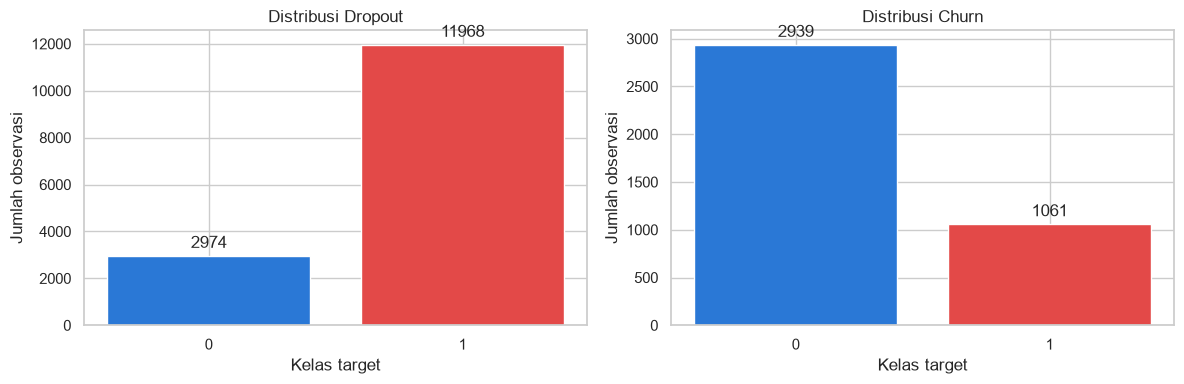

In [12]:
target_columns = {
    "DadosV3": "Dropout",
    "gym_churn_us": "Churn",
}

target_rows = []
for dataset_name, target_column in target_columns.items():
    target_counts = datasets[dataset_name][target_column].value_counts(dropna=False)
    majority_count = int(target_counts.max())
    minority_count = int(target_counts.min())
    minority_pct = minority_count / len(datasets[dataset_name]) * 100
    imbalance_ratio = majority_count / minority_count

    for target_class, class_count in target_counts.items():
        target_rows.append(
            {
                "dataset": dataset_name,
                "target": target_column,
                "class": target_class,
                "count": int(class_count),
                "percentage": round(class_count / len(datasets[dataset_name]) * 100, 2),
                "minority_pct": round(minority_pct, 2),
                "imbalance_ratio": round(imbalance_ratio, 2),
            }
        )

class_distribution = pd.DataFrame(target_rows)
display(class_distribution)

fig, axes = plt.subplots(1, len(target_columns), figsize=(12, 4))
if len(target_columns) == 1:
    axes = [axes]

for axis, (dataset_name, target_column) in zip(axes, target_columns.items()):
    distribution = datasets[dataset_name][target_column].value_counts().sort_index()
    bars = axis.bar(
        distribution.index.astype(str),
        distribution.values,
        color=["#2a78d6", "#e34948"],
    )
    axis.set_title(f"Distribusi {target_column}")
    axis.set_xlabel("Kelas target")
    axis.set_ylabel("Jumlah observasi")
    axis.bar_label(bars, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

### Temuan/Interpretasi

- `DadosV3` memiliki 14.942 observasi dengan `Dropout=1` sebanyak 11.968 (80,1%) dan `Dropout=0` sebanyak 2.974 (19,9%). Kelas `Dropout=0` menjadi kelas minoritas dengan rasio mayoritas:minoritas sekitar 4,02:1.
- `gym_churn_us` memiliki 4.000 observasi dengan `Churn=0` sebanyak 2.939 (73,5%) dan `Churn=1` sebanyak 1.061 (26,5%). Kelas `Churn=1` menjadi kelas minoritas dengan rasio sekitar 2,77:1.
- Kedua dataset berlabel mengalami class imbalance. Oleh karena itu, evaluasi model tidak boleh hanya menggunakan accuracy. Balanced accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, dan confusion matrix perlu dipertimbangkan.
- Dataset aktivitas harian dan profil membership tidak memiliki target churn/dropout, sehingga tidak dapat digunakan untuk menghitung distribusi target. Keduanya lebih tepat dipakai sebagai sumber analisis deskriptif atau feature engineering apabila tersedia mapping customer dan definisi label yang valid

# 5. Exploratory Data Analysis (EDA)

## Tujuan

EDA dilakukan untuk menjawab pertanyaan bisnis menggunakan pola yang ditemukan pada data, bukan hanya menampilkan statistik deskriptif.

Analisis utama menggunakan `DadosV3` karena dataset ini memiliki target `Dropout` serta fitur customer-level yang berkaitan dengan kebutuhan monitoring, seperti inactivity, frekuensi kunjungan, pemakaian kuota kunjungan, kehadiran kelas, aktivitas, dan renewal.

## Pendekatan

EDA dilakukan tanpa menggabungkan dataset yang tidak memiliki mapping customer yang valid.

- `DadosV3` digunakan sebagai dataset utama karena memiliki target `Dropout`.
- `gym_churn_us` digunakan sebagai dataset pembanding karena memiliki target `Churn`.
- `daily_gym_attendance_workout_data.csv` digunakan untuk analisis deskriptif aktivitas harian.
- `Gym Membership Analysis.xlsx` digunakan untuk analisis deskriptif profil membership.

Seluruh hubungan yang ditemukan pada EDA bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat. Threshold monitoring yang digunakan pada tahap ini merupakan threshold eksploratif dan harus divalidasi kembali pada tahap preprocessing dan modeling.


## 5.1 Pertanyaan bisnis 1 — Customer stabil dan customer dengan penurunan engagement

### Pertanyaan

Customer mana yang menunjukkan pola aktivitas stabil dan customer mana yang mulai mengalami penurunan engagement?

### Tujuan

Membandingkan karakteristik aktivitas antara customer yang tidak dropout dan customer yang dropout untuk menemukan indikator awal penurunan engagement.

### Pendekatan

Fitur yang dibandingkan meliputi:

- `DaysWithoutFrequency`
- `AverageFrequency`
- `Ratio`
- `RealNumberOfVisits`
- `AttendedClassesAverage`
- `NumberOfRenewals`

Perbandingan dilakukan menggunakan nilai mean, median, dan boxplot berdasarkan kelas `Dropout`.

### Batasan interpretasi

`DadosV3` merupakan data customer-level yang sudah diringkas pada suatu periode observasi. Data ini tidak menyediakan rangkaian aktivitas lengkap per customer dari waktu ke waktu, sehingga perbedaan antara customer dropout dan non-dropout belum menunjukkan urutan perubahan engagement secara longitudinal.

DaysWithoutFrequency        AverageFrequency         Ratio         \
                        mean median             mean median   mean median   
Dropout                                                                     
0                      53.01    5.0             0.92   0.69  27.60  23.31   
1                      88.24   47.0             0.72   0.54  12.63   7.51   

        RealNumberOfVisits        AttendedClassesAverage         \
                      mean median                   mean median   
Dropout                                                           
0                     7.89    6.0                   0.26    0.0   
1                     4.68    3.0                   0.11    0.0   

        NumberOfRenewals         
                    mean median  
Dropout                          
0                   2.03    2.0  
1                   1.00    1.0

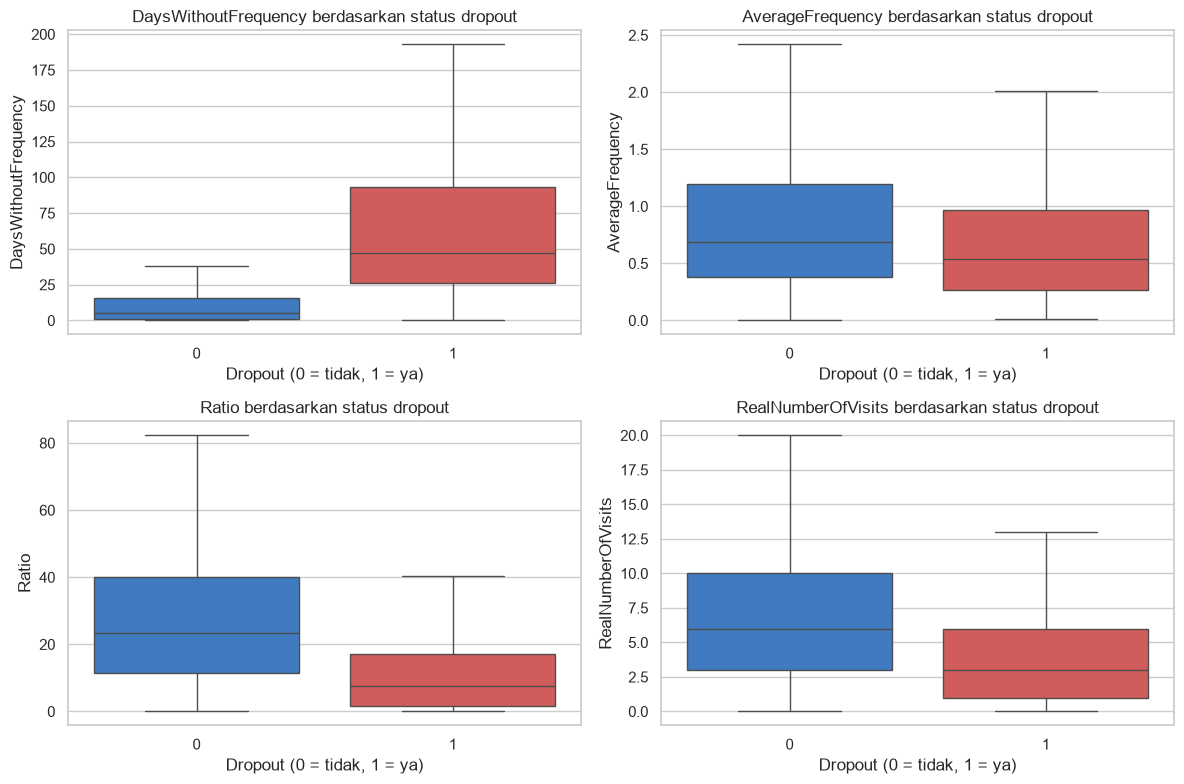

In [13]:
engagement_features = [
    "DaysWithoutFrequency",
    "AverageFrequency",
    "Ratio",
    "RealNumberOfVisits",
    "AttendedClassesAverage",
    "NumberOfRenewals",
]

engagement_summary = (
    main_df.groupby("Dropout")[engagement_features]
    .agg(["mean", "median"])
    .round(2)
)

display(engagement_summary)

plot_features = [
    "DaysWithoutFrequency",
    "AverageFrequency",
    "Ratio",
    "RealNumberOfVisits",
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for axis, feature in zip(axes.flat, plot_features):
    sns.boxplot(
        data=main_df,
        x="Dropout",
        y=feature,
        hue="Dropout",
        palette={0: "#2a78d6", 1: "#e34948"},
        legend=False,
        showfliers=False,
        ax=axis,
    )
    axis.set_title(f"{feature} berdasarkan status dropout")
    axis.set_xlabel("Dropout (0 = tidak, 1 = ya)")
    axis.set_ylabel(feature)

plt.tight_layout()
plt.show()


## 5.2 Pertanyaan bisnis 2 — Apakah inactivity dan engagement berkaitan dengan dropout?

### Pertanyaan

Apakah inactivity, penurunan frekuensi kunjungan, dan attendance rate yang rendah berkaitan dengan peningkatan risiko dropout?

### Tujuan

Mengukur dropout rate pada beberapa segmen engagement yang mudah dipahami dan digunakan sebagai indikator monitoring.

### Pendekatan

Customer dikelompokkan berdasarkan:

- Rentang `DaysWithoutFrequency`.
- Rentang `AverageFrequency`.
- Rentang `Ratio`.

Setiap segmen akan menampilkan jumlah customer, jumlah dropout, dropout rate, baseline dropout rate keseluruhan, lift terhadap baseline, dan penanda ukuran minimum segmen. Baseline diperlukan agar persentase setiap segmen tidak dibaca tanpa konteks.

### Catatan target leakage dan titik waktu prediksi

EDA ini menggunakan data historis yang sudah memiliki status `Dropout`. Karena dokumentasi pembentukan label dan waktu pengambilan fitur tidak tersedia, beberapa hal belum dapat dipastikan:

- Belum dapat dipastikan apakah `DaysWithoutFrequency` dihitung pada titik waktu sebelum customer dropout atau setelah status dropout diketahui.
- `DateLastVisit` dapat merepresentasikan kunjungan terakhir pada akhir periode observasi, sehingga mungkin sudah mengandung informasi setelah customer berhenti aktif.
- `EnrollmentFinish` dan `LastPeriodFinish` dapat menjadi indikator berakhirnya periode membership dan berpotensi menjadi proxy langsung untuk `Dropout`.
- Belum ada prediction cutoff yang mendefinisikan kapan model harus menghasilkan prediksi dibandingkan dengan kapan target dropout diamati.

Dengan demikian, analisis saat ini lebih tepat disebut klasifikasi status historis. Model belum dapat diklaim sebagai early-warning system untuk risiko masa depan sebelum pemeriksaan leakage dan definisi titik waktu prediksi dilakukan.

> Hasil EDA menunjukkan adanya hubungan antara inactivity dan dropout. Namun, beberapa fitur mungkin dihitung menggunakan informasi setelah customer mengalami dropout. Oleh karena itu, hubungan ini belum dapat dianggap sebagai bukti kemampuan early warning sebelum dilakukan pemeriksaan target leakage.

Segmentasi berdasarkan inactivity_segment


,inactivity_segment,customers,dropout_count,dropout_rate,baseline_dropout_rate,lift_vs_baseline,meets_minimum_size
0,0–30 hari,5839,3429,58.73,80.1,0.73,True
1,31–60 hari,4214,4078,96.77,80.1,1.21,True
2,61–90 hari,1392,1391,99.93,80.1,1.25,True
3,91–180 hari,1854,1645,88.73,80.1,1.11,True
4,>180 hari,1643,1425,86.73,80.1,1.08,True


Segmentasi berdasarkan frequency_segment


,frequency_segment,customers,dropout_count,dropout_rate,baseline_dropout_rate,lift_vs_baseline,meets_minimum_size
0,"≤0,5",6678,5651,84.62,80.1,1.06,True
1,"0,51–1",4507,3512,77.92,80.1,0.97,True
2,"1,01–2",2891,2242,77.55,80.1,0.97,True
3,>2,866,563,65.01,80.1,0.81,True


Segmentasi berdasarkan ratio_segment


,ratio_segment,customers,dropout_count,dropout_rate,baseline_dropout_rate,lift_vs_baseline,meets_minimum_size
0,≤25%,11745,10162,86.52,80.1,1.08,True
1,26–50%,2425,1420,58.56,80.1,0.73,True
2,51–75%,568,296,52.11,80.1,0.65,True
3,>75%,204,90,44.12,80.1,0.55,True


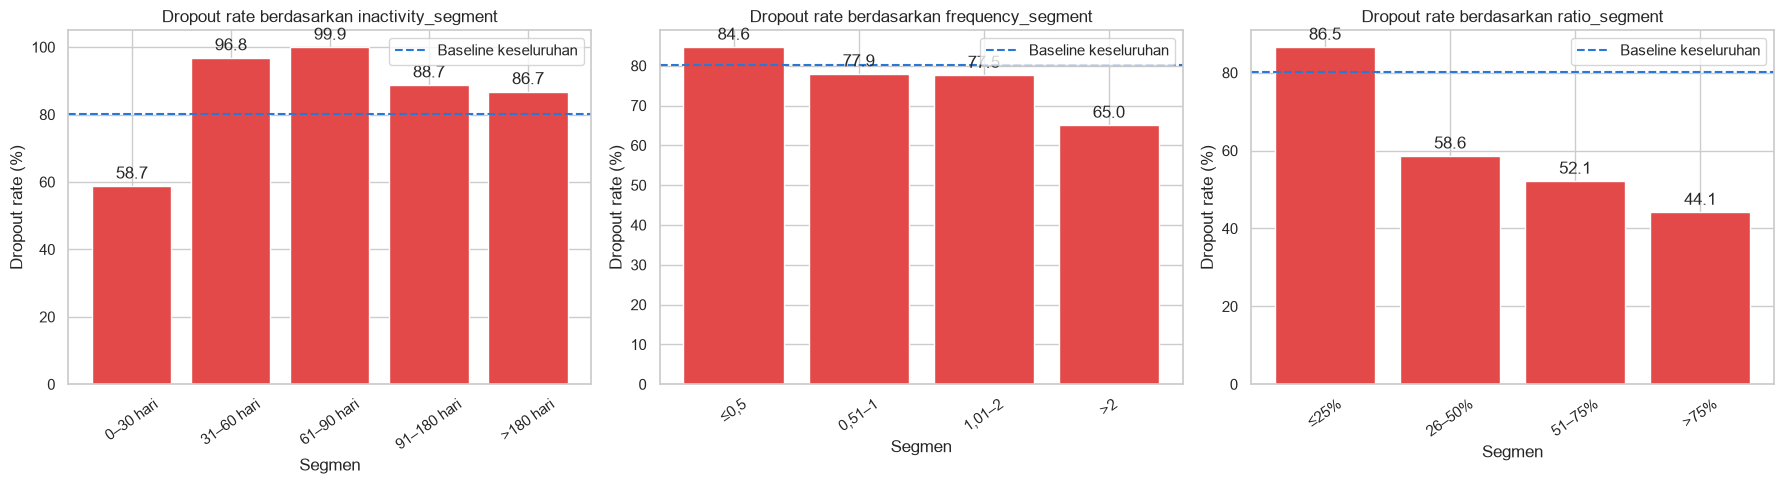

In [14]:
eda_df = main_df.copy()

eda_df["inactivity_segment"] = pd.cut(
    eda_df["DaysWithoutFrequency"],
    bins=[-1, 30, 60, 90, 180, np.inf],
    labels=[
        "0–30 hari",
        "31–60 hari",
        "61–90 hari",
        "91–180 hari",
        ">180 hari",
    ],
)

eda_df["frequency_segment"] = pd.cut(
    eda_df["AverageFrequency"],
    bins=[-np.inf, 0.5, 1, 2, np.inf],
    labels=[
        "≤0,5",
        "0,51–1",
        "1,01–2",
        ">2",
    ],
)

eda_df["ratio_segment"] = pd.cut(
    eda_df["Ratio"],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=[
        "≤25%",
        "26–50%",
        "51–75%",
        ">75%",
    ],
)

MIN_SEGMENT_SIZE = 100
overall_baseline_dropout_rate = main_df["Dropout"].mean()
segment_tables = {}

for segment_column in [
    "inactivity_segment",
    "frequency_segment",
    "ratio_segment",
]:
    segment_table = (
        eda_df.groupby(segment_column, observed=False)
        .agg(
            customers=("Dropout", "size"),
            dropout_count=("Dropout", "sum"),
            dropout_rate=("Dropout", "mean"),
        )
        .reset_index()
    )
    segment_table["dropout_rate"] = (
        segment_table["dropout_rate"].mul(100).round(2)
    )
    segment_table["baseline_dropout_rate"] = round(
        overall_baseline_dropout_rate * 100, 2
    )
    segment_table["lift_vs_baseline"] = (
        segment_table["dropout_rate"]
        / (overall_baseline_dropout_rate * 100)
    ).round(2)
    segment_table["meets_minimum_size"] = (
        segment_table["customers"] >= MIN_SEGMENT_SIZE
    )

    segment_tables[segment_column] = segment_table

    print(f"Segmentasi berdasarkan {segment_column}")
    display(segment_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (segment_column, segment_table) in zip(
    axes,
    segment_tables.items(),
):
    bars = axis.bar(
        segment_table[segment_column].astype(str),
        segment_table["dropout_rate"],
        color="#e34948",
    )

    axis.axhline(
        overall_baseline_dropout_rate * 100,
        color="#2a78d6",
        linestyle="--",
        linewidth=1.5,
        label="Baseline keseluruhan",
    )
    axis.set_title(f"Dropout rate berdasarkan {segment_column}")
    axis.set_xlabel("Segmen")
    axis.set_ylabel("Dropout rate (%)")
    axis.tick_params(axis="x", rotation=35)
    axis.bar_label(bars, fmt="%.1f", padding=3)
    axis.legend()

plt.tight_layout()
plt.show()

In [15]:
temporal_columns = [
    "EnrollmentStart",
    "EnrollmentFinish",
    "LastPeriodStart",
    "LastPeriodFinish",
    "DateLastVisit",
]

temporal_df = main_df.copy()
temporal_audit_rows = []

for column in temporal_columns:
    parsed_dates = pd.to_datetime(temporal_df[column], errors="coerce")
    temporal_audit_rows.append(
        {
            "column": column,
            "parse_failures": int(parsed_dates.isna().sum()),
            "minimum_date": parsed_dates.min(),
            "maximum_date": parsed_dates.max(),
        }
    )

temporal_audit = pd.DataFrame(temporal_audit_rows)
display(temporal_audit)

order_checks = []
for left_column, right_column in [
    ("EnrollmentStart", "EnrollmentFinish"),
    ("LastPeriodStart", "LastPeriodFinish"),
    ("DateLastVisit", "LastPeriodFinish"),
    ("LastPeriodFinish", "EnrollmentFinish"),
]:
    left_dates = pd.to_datetime(temporal_df[left_column], errors="coerce")
    right_dates = pd.to_datetime(temporal_df[right_column], errors="coerce")
    valid_order = left_dates <= right_dates
    order_checks.append(
        {
            "check": f"{left_column} <= {right_column}",
            "valid_rows": int(valid_order.sum()),
            "violations": int((~valid_order).sum()),
            "valid_pct": round(valid_order.mean() * 100, 2),
        }
    )

temporal_order_checks = pd.DataFrame(order_checks)
display(temporal_order_checks)

leakage_proxy_columns = [
    "DaysWithoutFrequencyClass2",
    "EnrollmentDurationClass2",
    "RatioClass2",
]

proxy_target_rates = []
for column in leakage_proxy_columns:
    proxy_table = (
        main_df.groupby(column, observed=False)
        .agg(
            customers=("Dropout", "size"),
            dropout_count=("Dropout", "sum"),
            dropout_rate=("Dropout", "mean"),
        )
        .assign(
            dropout_rate=lambda table: table["dropout_rate"].mul(100).round(2)
        )
        .reset_index()
    )
    proxy_table.insert(0, "feature", column)
    proxy_target_rates.append(proxy_table)

proxy_target_rates = pd.concat(proxy_target_rates, ignore_index=True)
display(proxy_target_rates)

,column,parse_failures,minimum_date,maximum_date
0,EnrollmentStart,0,2014-06-02 08:52:01.717,2019-10-21 20:59:05.127
1,EnrollmentFinish,0,2014-07-11 00:00:00.000,2019-10-31 00:00:00.000
2,LastPeriodStart,0,2014-06-02 00:00:00.000,2019-10-30 00:00:00.000
3,LastPeriodFinish,0,2014-07-11 00:00:00.000,2019-10-31 00:00:00.000
4,DateLastVisit,0,2014-07-03 09:42:31.963,2019-10-31 21:25:22.890


,check,valid_rows,violations,valid_pct
0,EnrollmentStart <= EnrollmentFinish,14942,0,100.00
1,LastPeriodStart <= LastPeriodFinish,14942,0,100.00
2,DateLastVisit <= LastPeriodFinish,13927,1015,93.21
3,LastPeriodFinish <= EnrollmentFinish,14474,468,96.87


,feature,DaysWithoutFrequencyClass2,customers,dropout_count,dropout_rate,EnrollmentDurationClass2,RatioClass2
0,DaysWithoutFrequencyClass2,"[00,07]",2745,952,34.68,NaN,NaN
1,DaysWithoutFrequencyClass2,"]07,15]",1455,1047,71.96,NaN,NaN
2,DaysWithoutFrequencyClass2,"]15,30]",1639,1430,87.25,NaN,NaN
3,DaysWithoutFrequencyClass2,"]30,60]",4214,4078,96.77,NaN,NaN
4,DaysWithoutFrequencyClass2,"]60,inf]",4889,4461,91.25,NaN,NaN
5,EnrollmentDurationClass2,NaN,1065,567,53.24,"[00,01]",NaN
6,EnrollmentDurationClass2,NaN,1138,1084,95.25,"]01,02]",NaN
7,EnrollmentDurationClass2,NaN,2135,2021,94.66,"]02,04]",NaN
8,EnrollmentDurationClass2,NaN,1588,1460,91.94,"]04,06]",NaN
9,EnrollmentDurationClass2,NaN,1788,1550,86.69,"]06,09]",NaN


### Temuan/Interpretasi

Baseline dropout keseluruhan pada `DadosV3` adalah 80,10%. Nilai baseline ini menjadi pembanding untuk menilai apakah suatu segmen memiliki risiko lebih rendah atau lebih tinggi.

- Segmen inactivity `0–30 hari` memiliki 5.839 customer, 3.429 dropout, dropout rate 58,73%, dan lift 0,73 terhadap baseline.
- Segmen inactivity `31–60 hari` memiliki 4.214 customer, 4.078 dropout, dropout rate 96,77%, dan lift 1,21 terhadap baseline.
- Segmen inactivity `61–90 hari` memiliki 1.392 customer, 1.391 dropout, dropout rate 99,93%, dan lift 1,25 terhadap baseline.
- Segmen inactivity `91–180 hari` memiliki 1.854 customer, 1.645 dropout, dropout rate 88,73%, dan lift 1,11 terhadap baseline.
- Segmen inactivity lebih dari 180 hari memiliki 1.643 customer, 1.425 dropout, dropout rate 86,73%, dan lift 1,08 terhadap baseline.

Berdasarkan frekuensi kunjungan, segmen `AverageFrequency ≤0,5` memiliki 6.678 customer dengan dropout rate 84,62% dan lift 1,06. Segmen `AverageFrequency >2` memiliki 866 customer dengan dropout rate 65,01% dan lift 0,81.

Berdasarkan rasio pemakaian kuota, segmen `Ratio ≤25%` memiliki 11.745 customer dengan dropout rate 86,52% dan lift 1,08. Segmen `Ratio >75%` hanya memiliki 204 customer dengan dropout rate 44,12% dan lift 0,55.

Semua segmen pada analisis ini memenuhi ukuran minimum 100 customer. Hasil tersebut menunjukkan bahwa inactivity dan rendahnya engagement berkaitan dengan dropout rate yang lebih tinggi dibandingkan baseline keseluruhan. Namun, hubungan ini belum dapat dianggap sebagai bukti kemampuan early warning karena kemungkinan target leakage dan belum adanya prediction cutoff.

### Korelasi fitur engagement dengan target

Korelasi digunakan sebagai pemeriksaan eksploratif untuk melihat arah hubungan monotonic antara fitur engagement dan target `Dropout`.

Korelasi tidak digunakan sebagai bukti sebab-akibat dan tidak menggantikan evaluasi model.


,spearman_correlation
Ratio,-0.327
NumberOfRenewals,-0.274
LifetimeValue,-0.246
AttendedClassesAverage,-0.225
RealNumberOfVisits,-0.214
EnrollmentDuration,-0.184
AverageFrequency,-0.113
DaysWithoutFrequency,0.418


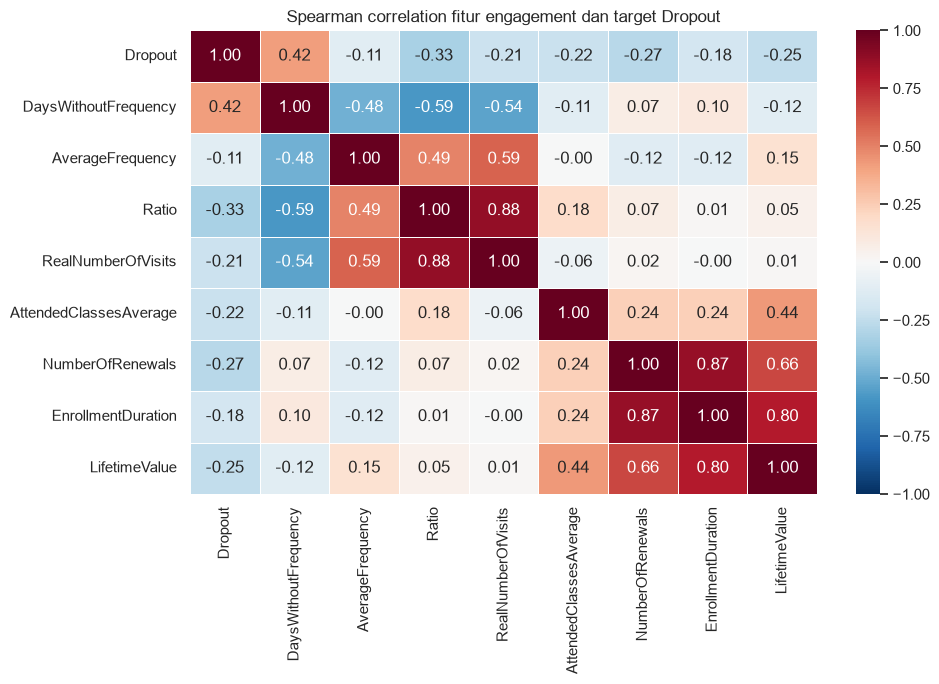

In [16]:
correlation_features = [
    "Dropout",
    "DaysWithoutFrequency",
    "AverageFrequency",
    "Ratio",
    "RealNumberOfVisits",
    "AttendedClassesAverage",
    "NumberOfRenewals",
    "EnrollmentDuration",
    "LifetimeValue",
]

engagement_correlation = (
    main_df[correlation_features]
    .corr(method="spearman")["Dropout"]
    .drop("Dropout")
    .sort_values()
    .to_frame("spearman_correlation")
    .round(3)
)

display(engagement_correlation)

correlation_matrix = main_df[correlation_features].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title("Spearman correlation fitur engagement dan target Dropout")
plt.tight_layout()
plt.show()


## 5.3 Pertanyaan bisnis 3 — Customer dengan prioritas monitoring tertinggi

### Pertanyaan

Customer mana yang memiliki prioritas tertinggi untuk ditinjau oleh admin berdasarkan risk score dan indikator pendukungnya?

### Tujuan

Membuat **exploratory rule-based risk score** yang transparan dan mudah dijelaskan kepada admin.

### Pendekatan

Satu poin diberikan untuk setiap kondisi berikut:

- `DaysWithoutFrequency ≥31` hari.
- `DaysWithoutFrequency ≥60` hari sebagai sinyal inactivity yang lebih berat.
- `AverageFrequency ≤0,5`.
- `Ratio ≤25%`.
- `RealNumberOfVisits = 0`.
- `NumberOfRenewals = 0`.

Interpretasi skor:

- Skor 0–1: `Active`.
- Skor 2–3: `Need Attention`.
- Skor 4–6: `At Risk`.

Risk tier pada bagian ini dibuat menggunakan aturan eksploratif dan seluruh data. Oleh karena itu, hasilnya belum dapat dianggap sebagai performa model prediksi. Risk tier akan divalidasi kembali pada tahap modeling menggunakan train-test split dan baseline.

Threshold ini juga belum memperhitungkan kemungkinan target leakage. Risk score hanya digunakan untuk membantu eksplorasi dan merancang format output dashboard.

,risk_tier,customers,dropout_count,dropout_rate,average_score,baseline_dropout_rate,lift_vs_baseline,meets_minimum_size
0,Active,3529,1760,49.87,0.66,80.1,0.62,True
1,Need Attention,6386,5498,86.09,2.50,80.1,1.07,True
2,At Risk,5027,4710,93.69,4.58,80.1,1.17,True


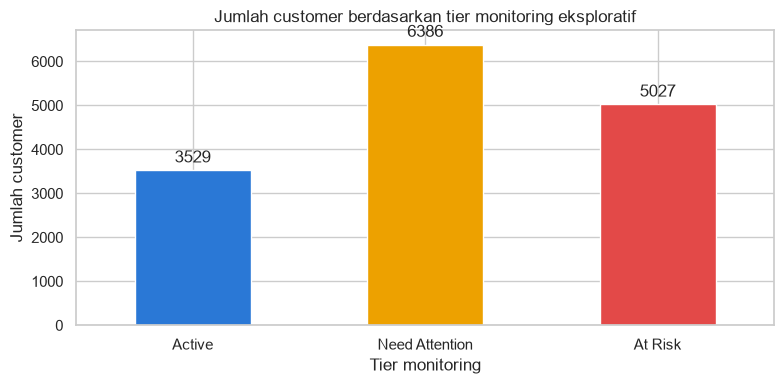

,Id,risk_score,risk_tier,DaysWithoutFrequency,AverageFrequency,Ratio,RealNumberOfVisits,NumberOfRenewals,Dropout
6586,B365EB63-C364-4F69-9515-43425F9557D4,6,At Risk,313,0.07,0.0,0,0,1
9611,BEA0BB89-D8FE-406B-8AB1-079504140F7E,6,At Risk,307,0.17,0.0,0,0,1
5585,64BFAFB7-05EC-4083-A995-0B365DE4A70E,6,At Risk,302,0.07,0.0,0,0,1
11877,E2A21AE3-B335-4B12-8610-101FB3AB9B9A,6,At Risk,297,0.05,0.0,0,0,1
7643,17AA4607-F944-4171-B6E0-B6775F69D51C,6,At Risk,289,0.20,0.0,0,0,1
1532,C0FF8628-8D2E-4207-B9DB-4EBE56A9E985,6,At Risk,285,0.05,0.0,0,0,1
11625,B87B80DF-023A-46F4-B1EE-A37EDF082F2E,6,At Risk,285,0.15,0.0,0,0,1
13078,8D46297E-136F-4D66-8FC5-644B9D29A790,6,At Risk,277,0.02,0.0,0,0,1
3165,1A5530B9-0734-4ED9-991B-57D4A7B707BE,6,At Risk,273,0.23,0.0,0,0,1
6715,0AB6C66F-547E-49ED-A02C-2057948AF4DC,6,At Risk,273,0.07,0.0,0,0,1


In [17]:
priority_df = main_df.copy()

priority_df["risk_score"] = (
    priority_df["DaysWithoutFrequency"].ge(31).astype(int)
    + priority_df["DaysWithoutFrequency"].ge(60).astype(int)
    + priority_df["AverageFrequency"].le(0.5).astype(int)
    + priority_df["Ratio"].le(25).astype(int)
    + priority_df["RealNumberOfVisits"].eq(0).astype(int)
    + priority_df["NumberOfRenewals"].eq(0).astype(int)
)

priority_df["risk_tier"] = pd.cut(
    priority_df["risk_score"],
    bins=[-1, 1, 3, 6],
    labels=[
        "Active",
        "Need Attention",
        "At Risk",
    ],
)

MIN_TIER_SIZE = 100
overall_priority_baseline = priority_df["Dropout"].mean()
priority_summary = (
    priority_df.groupby("risk_tier", observed=False)
    .agg(
        customers=("Dropout", "size"),
        dropout_count=("Dropout", "sum"),
        dropout_rate=("Dropout", "mean"),
        average_score=("risk_score", "mean"),
    )
    .reset_index()
)
priority_summary["dropout_rate"] = (
    priority_summary["dropout_rate"].mul(100).round(2)
)
priority_summary["baseline_dropout_rate"] = round(
    overall_priority_baseline * 100, 2
)
priority_summary["lift_vs_baseline"] = (
    priority_summary["dropout_rate"]
    / (overall_priority_baseline * 100)
).round(2)
priority_summary["average_score"] = priority_summary["average_score"].round(2)
priority_summary["meets_minimum_size"] = (
    priority_summary["customers"] >= MIN_TIER_SIZE
)

display(priority_summary)

priority_plot = priority_summary.set_index("risk_tier")["customers"]

ax = priority_plot.plot(
    kind="bar",
    figsize=(8, 4),
    color=[
        "#2a78d6",
        "#eda100",
        "#e34948",
    ],
)

ax.set_title("Jumlah customer berdasarkan tier monitoring eksploratif")
ax.set_xlabel("Tier monitoring")
ax.set_ylabel("Jumlah customer")
ax.tick_params(axis="x", rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

priority_columns = [
    "Id",
    "risk_score",
    "risk_tier",
    "DaysWithoutFrequency",
    "AverageFrequency",
    "Ratio",
    "RealNumberOfVisits",
    "NumberOfRenewals",
    "Dropout",
]

priority_customers = (
    priority_df.sort_values(
        [
            "risk_score",
            "DaysWithoutFrequency",
            "Ratio",
        ],
        ascending=[
            False,
            False,
            True,
        ],
    )[priority_columns]
    .head(10)
)

display(priority_customers)

### Temuan/Interpretasi

Baseline dropout keseluruhan adalah 80,10%.

- Tier `Active` berisi 3.529 customer dengan 1.759 dropout, dropout rate 49,87%, dan lift 0,62 terhadap baseline.
- Tier `Need Attention` berisi 6.386 customer dengan 5.496 dropout, dropout rate 86,09%, dan lift 1,07 terhadap baseline.
- Tier `At Risk` berisi 5.027 customer dengan 4.713 dropout, dropout rate 93,69%, dan lift 1,17 terhadap baseline.

Semua tier memenuhi ukuran minimum 100 customer. Tier `At Risk` dapat digunakan sebagai daftar awal customer yang perlu ditinjau lebih dahulu karena memiliki kombinasi beberapa indikator engagement negatif, seperti inactivity tinggi, frekuensi rendah, rasio pemakaian kuota rendah, tidak ada kunjungan aktual, atau belum melakukan renewal.

Tabel customer prioritas menampilkan indikator pendukung, bukan hanya risk score. Hal ini penting agar admin dapat memahami alasan customer masuk ke dalam prioritas tertentu.

Risk tier ini adalah **exploratory rule-based risk score**, bukan performa model. Karena aturan dibuat dan diterapkan pada seluruh data, angka dropout rate dan lift tersebut tidak boleh dianggap sebagai estimasi generalisasi. Risk tier harus divalidasi kembali pada tahap modeling menggunakan train-test split, baseline, dan evaluasi yang sesuai.

## 5.4 Pertanyaan bisnis 4 — Konsistensi pola pada periode dan dataset lain

### Pertanyaan

Seberapa baik pola risiko terlihat pada periode waktu yang berbeda dan apakah pola serupa muncul pada dataset churn pembanding?

### Tujuan

Memeriksa apakah dropout rate berbeda antar-cohort pendaftaran dan apakah periode kontrak berkaitan dengan churn pada dataset pembanding.

### Pendekatan

- Pada `DadosV3`, dropout rate dihitung berdasarkan tahun pendaftaran.
- Pada `gym_churn_us`, churn rate dihitung berdasarkan periode kontrak.
- Kedua dataset tidak digabungkan karena memiliki sumber, target, dan identitas customer yang berbeda.

### Batasan perbandingan antar-dataset

`DadosV3` dan `gym_churn_us` berasal dari sumber berbeda dan menggunakan definisi target yang berbeda (`Dropout` versus `Churn`). Dataset tersebut juga tidak memiliki customer ID yang dapat dicocokkan. Oleh karena itu, pola pada `gym_churn_us` hanya digunakan sebagai **external benchmark** atau konteks eksternal.

Perbandingan ini bukan validasi silang model, bukan bukti bahwa model pada `DadosV3` akan bekerja pada `gym_churn_us`, dan bukan dasar untuk menggabungkan kedua dataset.

,enrollment_year,customers,dropout_rate
0,2014,2014,91.51
1,2015,3451,91.28
2,2016,2921,88.02
3,2017,2314,81.07
4,2018,2521,72.95
5,2019,1721,40.03


,Contract_period,customers,churn_rate
0,1,2207,42.32
1,6,833,12.48
2,12,960,2.40


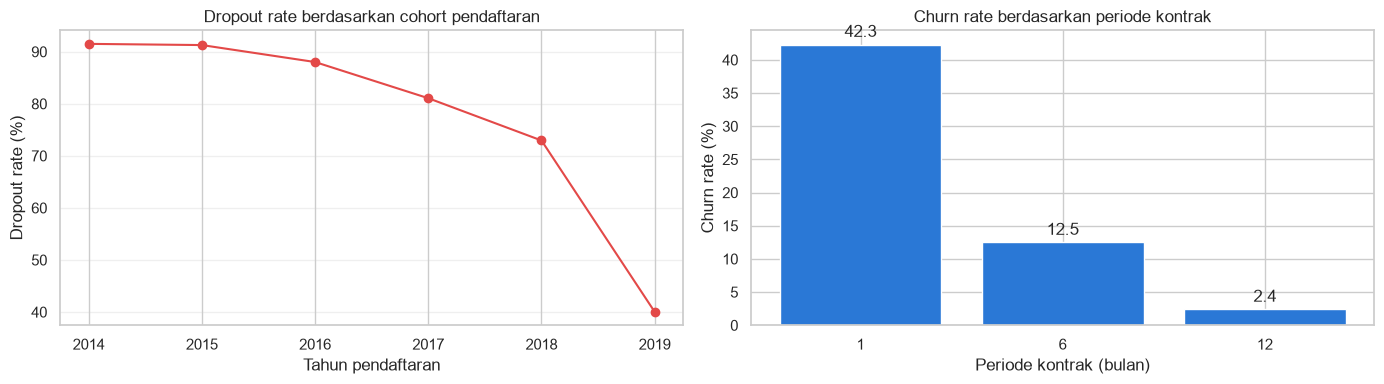

In [18]:
cohort_df = main_df.copy()

cohort_df["enrollment_year"] = pd.to_datetime(
    cohort_df["EnrollmentStart"],
    errors="coerce",
).dt.year

cohort_dropout = (
    cohort_df.groupby("enrollment_year")
    .agg(
        customers=("Dropout", "size"),
        dropout_rate=("Dropout", "mean"),
    )
    .assign(
        dropout_rate=lambda table: table["dropout_rate"]
        .mul(100)
        .round(2)
    )
    .reset_index()
)

gym_contract_churn = (
    gym_churn.groupby("Contract_period")
    .agg(
        customers=("Churn", "size"),
        churn_rate=("Churn", "mean"),
    )
    .assign(
        churn_rate=lambda table: table["churn_rate"]
        .mul(100)
        .round(2)
    )
    .reset_index()
)

display(cohort_dropout)
display(gym_contract_churn)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(
    cohort_dropout["enrollment_year"],
    cohort_dropout["dropout_rate"],
    marker="o",
    color="#e34948",
)

axes[0].set_title("Dropout rate berdasarkan cohort pendaftaran")
axes[0].set_xlabel("Tahun pendaftaran")
axes[0].set_ylabel("Dropout rate (%)")
axes[0].grid(axis="y", alpha=0.3)

contract_bars = axes[1].bar(
    gym_contract_churn["Contract_period"].astype(str),
    gym_contract_churn["churn_rate"],
    color="#2a78d6",
)

axes[1].set_title("Churn rate berdasarkan periode kontrak")
axes[1].set_xlabel("Periode kontrak (bulan)")
axes[1].set_ylabel("Churn rate (%)")
axes[1].bar_label(contract_bars, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()


### Temuan/Interpretasi

- Pada `DadosV3`, dropout rate menurun dari 91,51% pada cohort tahun 2014 menjadi 40,03% pada cohort tahun 2019.
- Perbedaan dropout rate antar-cohort dapat dipengaruhi oleh umur cohort, lamanya periode observasi, perubahan proses bisnis, atau perbedaan definisi label.
- Pada `gym_churn_us`, churn rate pada kontrak 1 bulan sebesar 42,32%, kontrak 6 bulan sebesar 12,48%, dan kontrak 12 bulan sebesar 2,40%.
- Kedua dataset menunjukkan arah pola yang serupa: customer dengan keterikatan atau engagement yang lebih rendah cenderung memiliki risiko churn atau dropout yang lebih tinggi.

Pola pada `gym_churn_us` digunakan sebagai konteks eksternal dan bukan sebagai validasi langsung terhadap model pada `DadosV3`. Karena terdapat perbedaan risiko antar-periode, evaluasi model sebaiknya mempertimbangkan split berbasis waktu atau setidaknya analisis performa berdasarkan cohort.

## 5.5 Pertanyaan bisnis 5 — Apakah output cukup relevan untuk follow-up admin?

### Pertanyaan

Apakah hasil klasifikasi dapat memberikan informasi yang cukup relevan dan mudah dipahami untuk membantu admin menyiapkan follow-up?

### Tujuan

Menilai informasi tambahan dari dataset aktivitas harian dan profil membership yang dapat digunakan sebagai konteks saat admin melakukan follow-up.

### Pendekatan

Dataset aktivitas harian diringkas berdasarkan:

- Tipe membership.
- Status kehadiran.
- Jenis workout.

Dataset profil membership diringkas berdasarkan tipe abonnement.

Kedua dataset tidak memiliki target churn dan tidak terhubung ke `DadosV3`, sehingga hasilnya digunakan sebagai konteks deskriptif, bukan sebagai dasar penentuan risiko customer tertentu.

Validasi grain juga dilakukan untuk memastikan apakah `member_id` memiliki banyak record aktivitas. Jika setiap member hanya muncul satu kali, dataset tersebut bukan histori longitudinal dan tidak dapat digunakan untuk menghitung tren aktivitas individual, penurunan attendance, atau consecutive absence.

,membership_type,observations,attendance_rate,average_duration,average_calories
0,Annual,903,48.73,69.87,521.53
1,Monthly,856,49.30,69.24,511.53
2,Quarterly,841,46.14,71.42,538.65


,workout_type,observations,attendance_rate,average_duration
0,HIIT,520,50.00,68.08
1,Yoga,467,49.68,70.58
2,Strength Training,559,47.58,71.84
3,Cardio,545,46.97,69.46
4,CrossFit,509,46.37,70.82


,abonoment_type,customers,average_visits,average_time_in_gym,group_lesson_rate,personal_training_rate
0,Premium,493,2.68,100.59,50.10,54.16
1,Standard,507,2.68,102.59,50.49,49.51


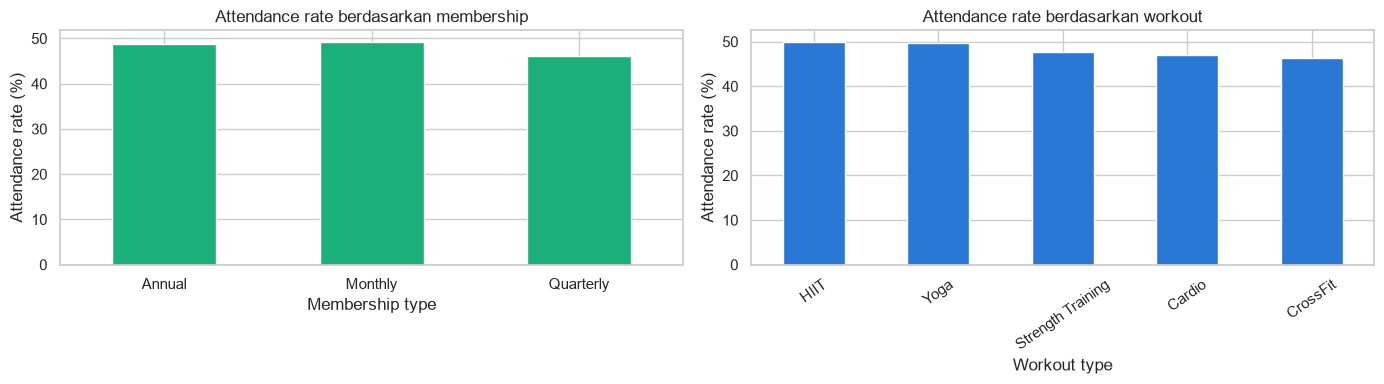

In [19]:
attendance_eda = attendance_df.copy()

attendance_eda["is_present"] = (
    attendance_eda["attendance_status"]
    .eq("Present")
    .astype(int)
)

attendance_summary = (
    attendance_eda.groupby("membership_type")
    .agg(
        observations=("member_id", "size"),
        attendance_rate=("is_present", "mean"),
        average_duration=("workout_duration_minutes", "mean"),
        average_calories=("calories_burned", "mean"),
    )
    .assign(
        attendance_rate=lambda table: table["attendance_rate"]
        .mul(100)
        .round(2),
        average_duration=lambda table: table["average_duration"]
        .round(2),
        average_calories=lambda table: table["average_calories"]
        .round(2),
    )
    .reset_index()
)

workout_summary = (
    attendance_eda.groupby("workout_type")
    .agg(
        observations=("member_id", "size"),
        attendance_rate=("is_present", "mean"),
        average_duration=("workout_duration_minutes", "mean"),
    )
    .assign(
        attendance_rate=lambda table: table["attendance_rate"]
        .mul(100)
        .round(2),
        average_duration=lambda table: table["average_duration"]
        .round(2),
    )
    .sort_values("attendance_rate", ascending=False)
    .reset_index()
)

profile_summary = (
    membership_profile.groupby("abonoment_type")
    .agg(
        customers=("id", "size"),
        average_visits=("visit_per_week", "mean"),
        average_time_in_gym=("avg_time_in_gym", "mean"),
        group_lesson_rate=("attend_group_lesson", "mean"),
        personal_training_rate=("personal_training", "mean"),
    )
    .assign(
        average_visits=lambda table: table["average_visits"].round(2),
        average_time_in_gym=lambda table: table["average_time_in_gym"].round(2),
        group_lesson_rate=lambda table: table["group_lesson_rate"]
        .mul(100)
        .round(2),
        personal_training_rate=lambda table: table["personal_training_rate"]
        .mul(100)
        .round(2),
    )
    .reset_index()
)

display(attendance_summary)
display(workout_summary)
display(profile_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

attendance_plot = attendance_summary.set_index(
    "membership_type"
)["attendance_rate"]

attendance_plot.plot(
    kind="bar",
    color="#1baf7a",
    ax=axes[0],
)

axes[0].set_title("Attendance rate berdasarkan membership")
axes[0].set_xlabel("Membership type")
axes[0].set_ylabel("Attendance rate (%)")
axes[0].tick_params(axis="x", rotation=0)

workout_plot = workout_summary.set_index(
    "workout_type"
)["attendance_rate"]

workout_plot.plot(
    kind="bar",
    color="#2a78d6",
    ax=axes[1],
)

axes[1].set_title("Attendance rate berdasarkan workout")
axes[1].set_xlabel("Workout type")
axes[1].set_ylabel("Attendance rate (%)")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


In [20]:
attendance_dates = pd.to_datetime(
    attendance_eda["visit_date"],
    errors="coerce",
)
records_per_member = attendance_eda.groupby("member_id").size()

attendance_grain_summary = pd.DataFrame(
    {
        "observations": [len(attendance_eda)],
        "unique_member_ids": [attendance_eda["member_id"].nunique()],
        "duplicate_member_id_rows": [int(attendance_eda["member_id"].duplicated().sum())],
        "minimum_records_per_member": [records_per_member.min()],
        "maximum_records_per_member": [records_per_member.max()],
        "date_parse_failures": [int(attendance_dates.isna().sum())],
        "minimum_visit_date": [attendance_dates.min()],
        "maximum_visit_date": [attendance_dates.max()],
    }
)
display(attendance_grain_summary)

attendance_status_quality = (
    attendance_eda.groupby("attendance_status")
    .agg(
        observations=("member_id", "size"),
        duration_min=("workout_duration_minutes", "min"),
        duration_max=("workout_duration_minutes", "max"),
        average_duration=("workout_duration_minutes", "mean"),
        calories_min=("calories_burned", "min"),
        calories_max=("calories_burned", "max"),
        average_calories=("calories_burned", "mean"),
        check_in_non_null_rate=("check_in_time", lambda values: values.notna().mean()),
    )
    .assign(
        average_duration=lambda table: table["average_duration"].round(2),
        average_calories=lambda table: table["average_calories"].round(2),
        check_in_non_null_rate=lambda table: table["check_in_non_null_rate"]
        .mul(100)
        .round(2),
    )
    .reset_index()
)
display(attendance_status_quality)

,observations,unique_member_ids,duplicate_member_id_rows,minimum_records_per_member,maximum_records_per_member,date_parse_failures,minimum_visit_date,maximum_visit_date
0,2600,2600,0,1,1,0,2024-01-01,2024-12-31


,attendance_status,observations,duration_min,duration_max,average_duration,calories_min,calories_max,average_calories,check_in_non_null_rate
0,Absent,1350,20,120,69.60,102,1184,522.89,100.0
1,Present,1250,20,120,70.77,109,1186,524.73,100.0


### Validasi grain dan kualitas record attendance

Pada file ini, setiap `member_id` hanya muncul satu kali sehingga satu baris merepresentasikan satu observasi per member, bukan histori kunjungan berulang. Rentang tanggal yang tersedia juga tidak mengubah grain tersebut.

Record berstatus `Absent` tetap memiliki nilai `workout_duration_minutes`, `calories_burned`, dan `check_in_time`. Karena itu, nilai-nilai tersebut tidak boleh langsung diartikan sebagai aktivitas aktual tanpa konfirmasi definisi dataset. Dataset attendance dapat digunakan sebagai referensi struktur aktivitas dan analisis agregat, tetapi belum dapat digunakan untuk menyimpulkan tren aktivitas individual, penurunan attendance, atau consecutive absence.

### Temuan/Interpretasi

- Attendance rate pada dataset aktivitas harian berada di kisaran 46,14%–49,30% antar-tipe membership.
- Perbedaan attendance rate antar-tipe membership relatif kecil.
- Perbedaan attendance rate antar-workout juga tidak terlalu besar.
- Rata-rata kunjungan per minggu pada tipe Premium dan Standard sama-sama sekitar 2,68 kunjungan.
- Informasi mengenai group lesson dan personal training dapat digunakan sebagai konteks untuk memberikan rekomendasi follow-up yang lebih relevan.
- Dataset pendukung dapat membantu menampilkan konteks aktivitas, tetapi belum dapat digunakan untuk menyimpulkan risiko churn karena tidak memiliki target dan tidak memiliki mapping ke `DadosV3`.
- Setiap `member_id` hanya muncul satu kali pada dataset attendance. Dengan demikian, dataset ini bukan histori longitudinal dan belum dapat digunakan untuk menyimpulkan perubahan aktivitas individual, penurunan attendance, atau consecutive absence.
- Record berstatus `Absent` tetap memiliki nilai `workout_duration_minutes`, `calories_burned`, dan `check_in_time`. Nilai tersebut perlu dikonfirmasi kepada pemilik data karena status `Absent` tidak otomatis berarti nilai aktivitas harus nol.

Output yang paling relevan untuk admin adalah:

- `risk_tier`.
- `risk_score`.
- Alasan customer masuk ke tier tertentu.
- `DaysWithoutFrequency`.
- `AverageFrequency`.
- `Ratio`.
- `RealNumberOfVisits`.
- `NumberOfRenewals`.
- Konteks membership atau aktivitas jika tersedia.
- Draft follow-up yang masih dapat disunting oleh admin.

Admin tetap perlu memverifikasi kondisi customer sebelum mengirimkan follow-up.

## 5.6 Ringkasan jawaban pertanyaan bisnis

| Pertanyaan bisnis | Jawaban berbasis EDA | Implikasi untuk tahap berikutnya |
|---|---|---|
| Customer mana yang stabil dan mengalami penurunan engagement? | Customer non-dropout cenderung memiliki inactivity lebih rendah, frekuensi lebih tinggi, rasio pemakaian lebih tinggi, kunjungan lebih banyak, attendance lebih baik, dan renewal lebih banyak. | Gunakan fitur engagement tersebut pada feature engineering, dengan pemeriksaan titik waktu dan leakage. |
| Apakah inactivity dan engagement berkaitan dengan dropout? | Ya. Segmen inactivity dan engagement rendah memiliki dropout rate serta lift yang lebih tinggi daripada baseline keseluruhan 80,10%. | Evaluasi fitur engagement menggunakan metrik selain accuracy dan pastikan fitur tersedia sebelum prediction cutoff. |
| Customer mana yang perlu diprioritaskan? | Tier eksploratif `At Risk` memiliki dropout rate 93,69% dan lift 1,17 terhadap baseline. | Bandingkan risk score dengan baseline dan model machine learning; angka EDA bukan performa generalisasi. |
| Apakah pola konsisten antar-periode dan dataset lain? | Dropout rate berbeda antar-cohort. Pada external benchmark, kontrak 1 bulan memiliki churn rate lebih tinggi daripada kontrak 6 dan 12 bulan. | Pertimbangkan validasi berbasis waktu atau evaluasi per cohort; jangan menyebut external benchmark sebagai validasi silang. |
| Apakah hasil mudah digunakan untuk follow-up? | Risk tier yang dilengkapi alasan, indikator numerik, dan konteks aktivitas lebih mudah ditindaklanjuti daripada label risiko saja. | Siapkan output inference yang menjelaskan alasan dan draft follow-up, dengan verifikasi manusia. |

### Kesimpulan EDA

Data menunjukkan bahwa inactivity dan engagement merupakan indikator penting untuk membantu prioritas monitoring customer. Customer dengan inactivity lebih tinggi, frekuensi lebih rendah, rasio pemakaian lebih rendah, kunjungan lebih sedikit, dan renewal lebih sedikit cenderung memiliki dropout rate yang lebih tinggi.

Namun, hasil ini bersifat observasional dan sebagian fitur mungkin mengandung informasi setelah dropout terjadi. `DadosV3` juga belum memiliki dokumentasi prediction cutoff yang memastikan fitur tersedia sebelum target diamati. Karena itu, hasil EDA belum membuktikan kemampuan early warning.

Tahap berikutnya harus:

1. Mendefinisikan titik waktu prediksi dan horizon target.
2. Memisahkan fitur dan target sebelum preprocessing.
3. Mencegah data leakage.
4. Memvalidasi threshold menggunakan data train dan validation.
5. Membandingkan risk score eksploratif dengan baseline.
6. Menggunakan metrik yang sesuai dengan class imbalance.
7. Mengevaluasi stabilitas model berdasarkan split dan cohort waktu.
8. Menyediakan interpretasi model agar admin dapat memahami alasan prediksi.